# 2. Long-Run Growth

# 2.1. Overview

This notebook uses Python, pandas, and Matplotlib to download, extract, and visualize historical economic growth data. This provides a basis for the techniques underpinning economic modeling. Additionally, we will use this to understand facts about economic growth in countries around the globe over the past several centuries.

Over the course of this notebook we will construct two graphs. The first is a reproduction of work from [[Tooze, 2014](https://intro.quantecon.org/zreferences.html#id16)], tracking the GDP of several countries from the early-mid 19th century up through the mid 20th century. The second will be an update to this plot, tracking growth through the early part of the 21st century.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

import numpy as np
from collections import namedtuple

from qe_custom import data_dir

## 2.2. Setting Up

QuantEcon uses data from the [Maddison Historical Statistics project](https://www.rug.nl/ggdc/historicaldevelopment/maddison/) initiated by Angus Maddision. The authors of QuantEcon provide their own set of this data from a QuantEcon GitHub repository. However more up-to-data data is available from the Maddison Historical Statistics project directly through the "Latest Maddison Project Release" link.

This repo contains two versions of this data: the canonical dataset provided by QuantEcon, for validation of our results against QuantEcon's lectures, and the 2023 version of the data from the Maddison Historical Statistics page, which is the latest release as of this writing. This will let us see how the landscape has changed since 2018, which is when QuantEcon's data ends.

To move between these two datasets, we define a wrapper function allowing selection of the version used in this notebook. To see the results using a different version, simply change the dataset that's loaded and re-run the notebook.

In [2]:
from qe_custom.data import load_data

# Load the 2020 data
data = load_data(version="2020")

# Display the first few rows of the downloaded data
data.head()

,countrycode,country,year,gdppc,pop
0,AFG,Afghanistan,1820,NaN,3280.0
1,AFG,Afghanistan,1870,NaN,4207.0
2,AFG,Afghanistan,1913,NaN,5730.0
3,AFG,Afghanistan,1950,1156.0,8150.0
4,AFG,Afghanistan,1951,1170.0,8284.0


We can see this contains information such as GDP per capita (gdppc) and population (pop) for many countries an years. We can examine how many countries and which countries are contained in the dataset next.

In [3]:
countries = data.country.unique()
len(countries)

169

Next we'll loop over the countries to see what is available and the year ranges present.

In [4]:
country_years = []
for country in countries:
    cy_data = data[data.country == country]["year"]
    ymin, ymax = cy_data.min(), cy_data.max()
    country_years.append((country, ymin, ymax))
country_years = pd.DataFrame(
    country_years, columns=["country", "min_year", "max_year"]
).set_index("country")
country_years.head()

,min_year,max_year
country,,
Afghanistan,1820,2018
Angola,1950,2018
Albania,1,2018
United Arab Emirates,1950,2018
Argentina,1800,2018


Next we'll build two data structures. The first is a mapping from country code to country name, allowing us to easily move between the two formats.

In [5]:
code_to_name = (
    data[["countrycode", "country"]]
    .drop_duplicates()
    .reset_index(drop=True)
    .set_index(["countrycode"])
)

The second is a wide format of our data, with years as rows and country codes as columns.

In [6]:
gdp_pc = data.set_index(["countrycode", "year"])["gdppc"]
gdp_pc = gdp_pc.unstack("countrycode")
gdp_pc.tail()

countrycode,AFG,AGO,ALB,ARE,ARG,ARM,AUS,AUT,AZE,BDI,...,URY,USA,UZB,VEN,VNM,YEM,YUG,ZAF,ZMB,ZWE
year,,,,,,,,,,,,,,,,,,,,,
2014,2022.0000,8673.0000,9808.0000,72601.0000,19183.0000,9735.0000,47867.0000,41338.0000,17439.0000,748.0000,...,19160.0000,51664.0000,9085.0000,20317.0000,5455.0000,4054.0000,14627.0000,12242.0000,3478.0000,1594.0000
2015,1928.0000,8689.0000,10032.0000,74746.0000,19502.0000,10042.0000,48357.0000,41294.0000,17460.0000,694.0000,...,19244.0000,52591.0000,9720.0000,18802.0000,5763.0000,2844.0000,14971.0000,12246.0000,3478.0000,1560.0000
2016,1929.0000,8453.0000,10342.0000,75876.0000,18875.0000,10080.0000,48845.0000,41445.0000,16645.0000,665.0000,...,19468.0000,53015.0000,10381.0000,15219.0000,6062.0000,2506.0000,15416.0000,12139.0000,3479.0000,1534.0000
2017,2014.7453,8146.4354,10702.1201,76643.4984,19200.9061,10859.3783,49265.6135,42177.3706,16522.3072,671.3169,...,19918.1361,54007.7698,10743.8666,12879.1350,6422.0865,2321.9239,15960.8432,12189.3579,3497.5818,1582.3662
2018,1934.5550,7771.4418,11104.1665,76397.8181,18556.3831,11454.4251,49830.7993,42988.0709,16628.0553,651.3589,...,20185.8360,55334.7394,11220.3702,10709.9506,6814.1423,2284.8899,16558.3123,12165.7948,3534.0337,1611.4052


Finally, we also create a `color_mapping` variable to keep the colors for each country consistent.

In [7]:
country_names = data["countrycode"]

# Generate a colormap with the number of colors matching the number of countries
colors = cm.tab20(np.linspace(0, 0.95, len(country_names)))

# Create a dictionary to map each country to its corresponding color
color_mapping = {
    country: color for country, color in zip(country_names, colors)
}

## 2.3. GDP per Capita

Next we'll examine long-run GDP per capita for several countries.

### 2.3.1. United Kingdom

First we examine UK GDP growth.

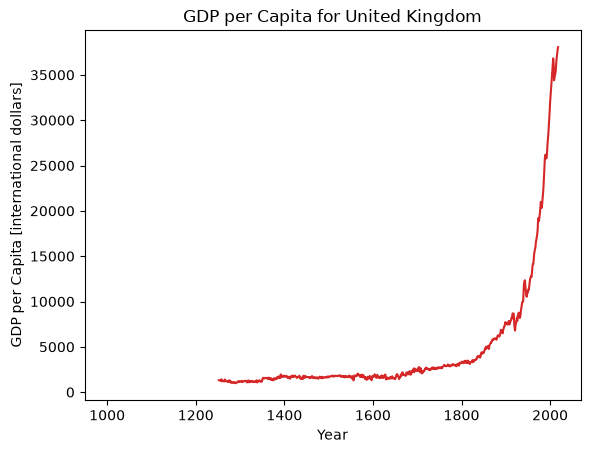

In [8]:
fig, ax = plt.subplots()
country = "GBR"  # Example country code for the United Kingdom
# Plot the GDP per capita for the selected country
gdp_pc[country].plot(
    ax=ax,
    color=color_mapping[country],
    xlabel="Year",
    ylabel="GDP per Capita [international dollars]",
    title=f'GDP per Capita for {code_to_name.loc[country]["country"]}',
)
plt.show()

We can see that data prior to about 1250 CE is missing. To get a continuous trend through this period, we can interpolate the data. We use a dashed line to indicate the interpolated period.

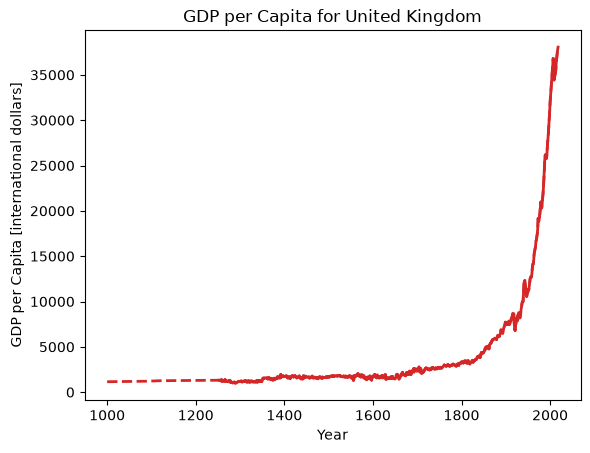

In [9]:
fig, ax = plt.subplots()
country = "GBR"
ax.plot(
    gdp_pc[country].interpolate(),
    linestyle="--",
    lw=2,
    color=color_mapping[country],
)

ax.plot(gdp_pc[country], lw=2, color=color_mapping[country])
ax.set_ylabel("GDP per Capita [international dollars]")
ax.set_xlabel("Year")
ax.set_title(f'GDP per Capita for {code_to_name.loc[country]["country"]}')
plt.show()

### 2.3.2. Comparing the US, UK, and China

Next we compare historic GDP for the US, UK, and China. We start by defining a function to build our plots.

In [10]:
def draw_interp_plots(
    series,  # pandas series
    country,  # list of country codes
    ylabel,  # label for y-axis
    xlabel,  # label for x-axis
    color_mapping,  # code-color mapping
    code_to_name,  # code-name mapping
    lw,  # line width
    logscale,  # log scale for y-axis
    ax,  # matplolib axis
):

    for c in country:
        # Get the interpolated data
        df_interpolated = series[c].interpolate(limit_area="inside")
        interpolated_data = df_interpolated[series[c].isnull()]

        # Plot the interpolated data with dashed lines
        ax.plot(
            interpolated_data,
            linestyle="--",
            lw=lw,
            alpha=0.7,
            color=color_mapping[c],
        )

        # Plot the non-interpolated data with solid lines
        ax.plot(
            series[c],
            lw=lw,
            color=color_mapping[c],
            alpha=0.8,
            label=code_to_name.loc[c]["country"],
        )

        if logscale:
            ax.set_yscale("log")

    # Draw the legend outside the plot
    ax.legend(loc="upper left", frameon=False)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)

Next we plot historic GDP trends for the US, UK, and China. To add more historical context, we also denote important events in the plot, including the Navigation Act (1651) and its repeal (1849) in the UK, China's closed door policy (1655-1684), the American revolution (1765-1791) and civil war (1861-1865), the Industrial Revolution (1760-1840), World War I (1914-1918), the Great Depression (1929-1939), World War II (1939-1945), and the reform and opening of China (1978-1979).

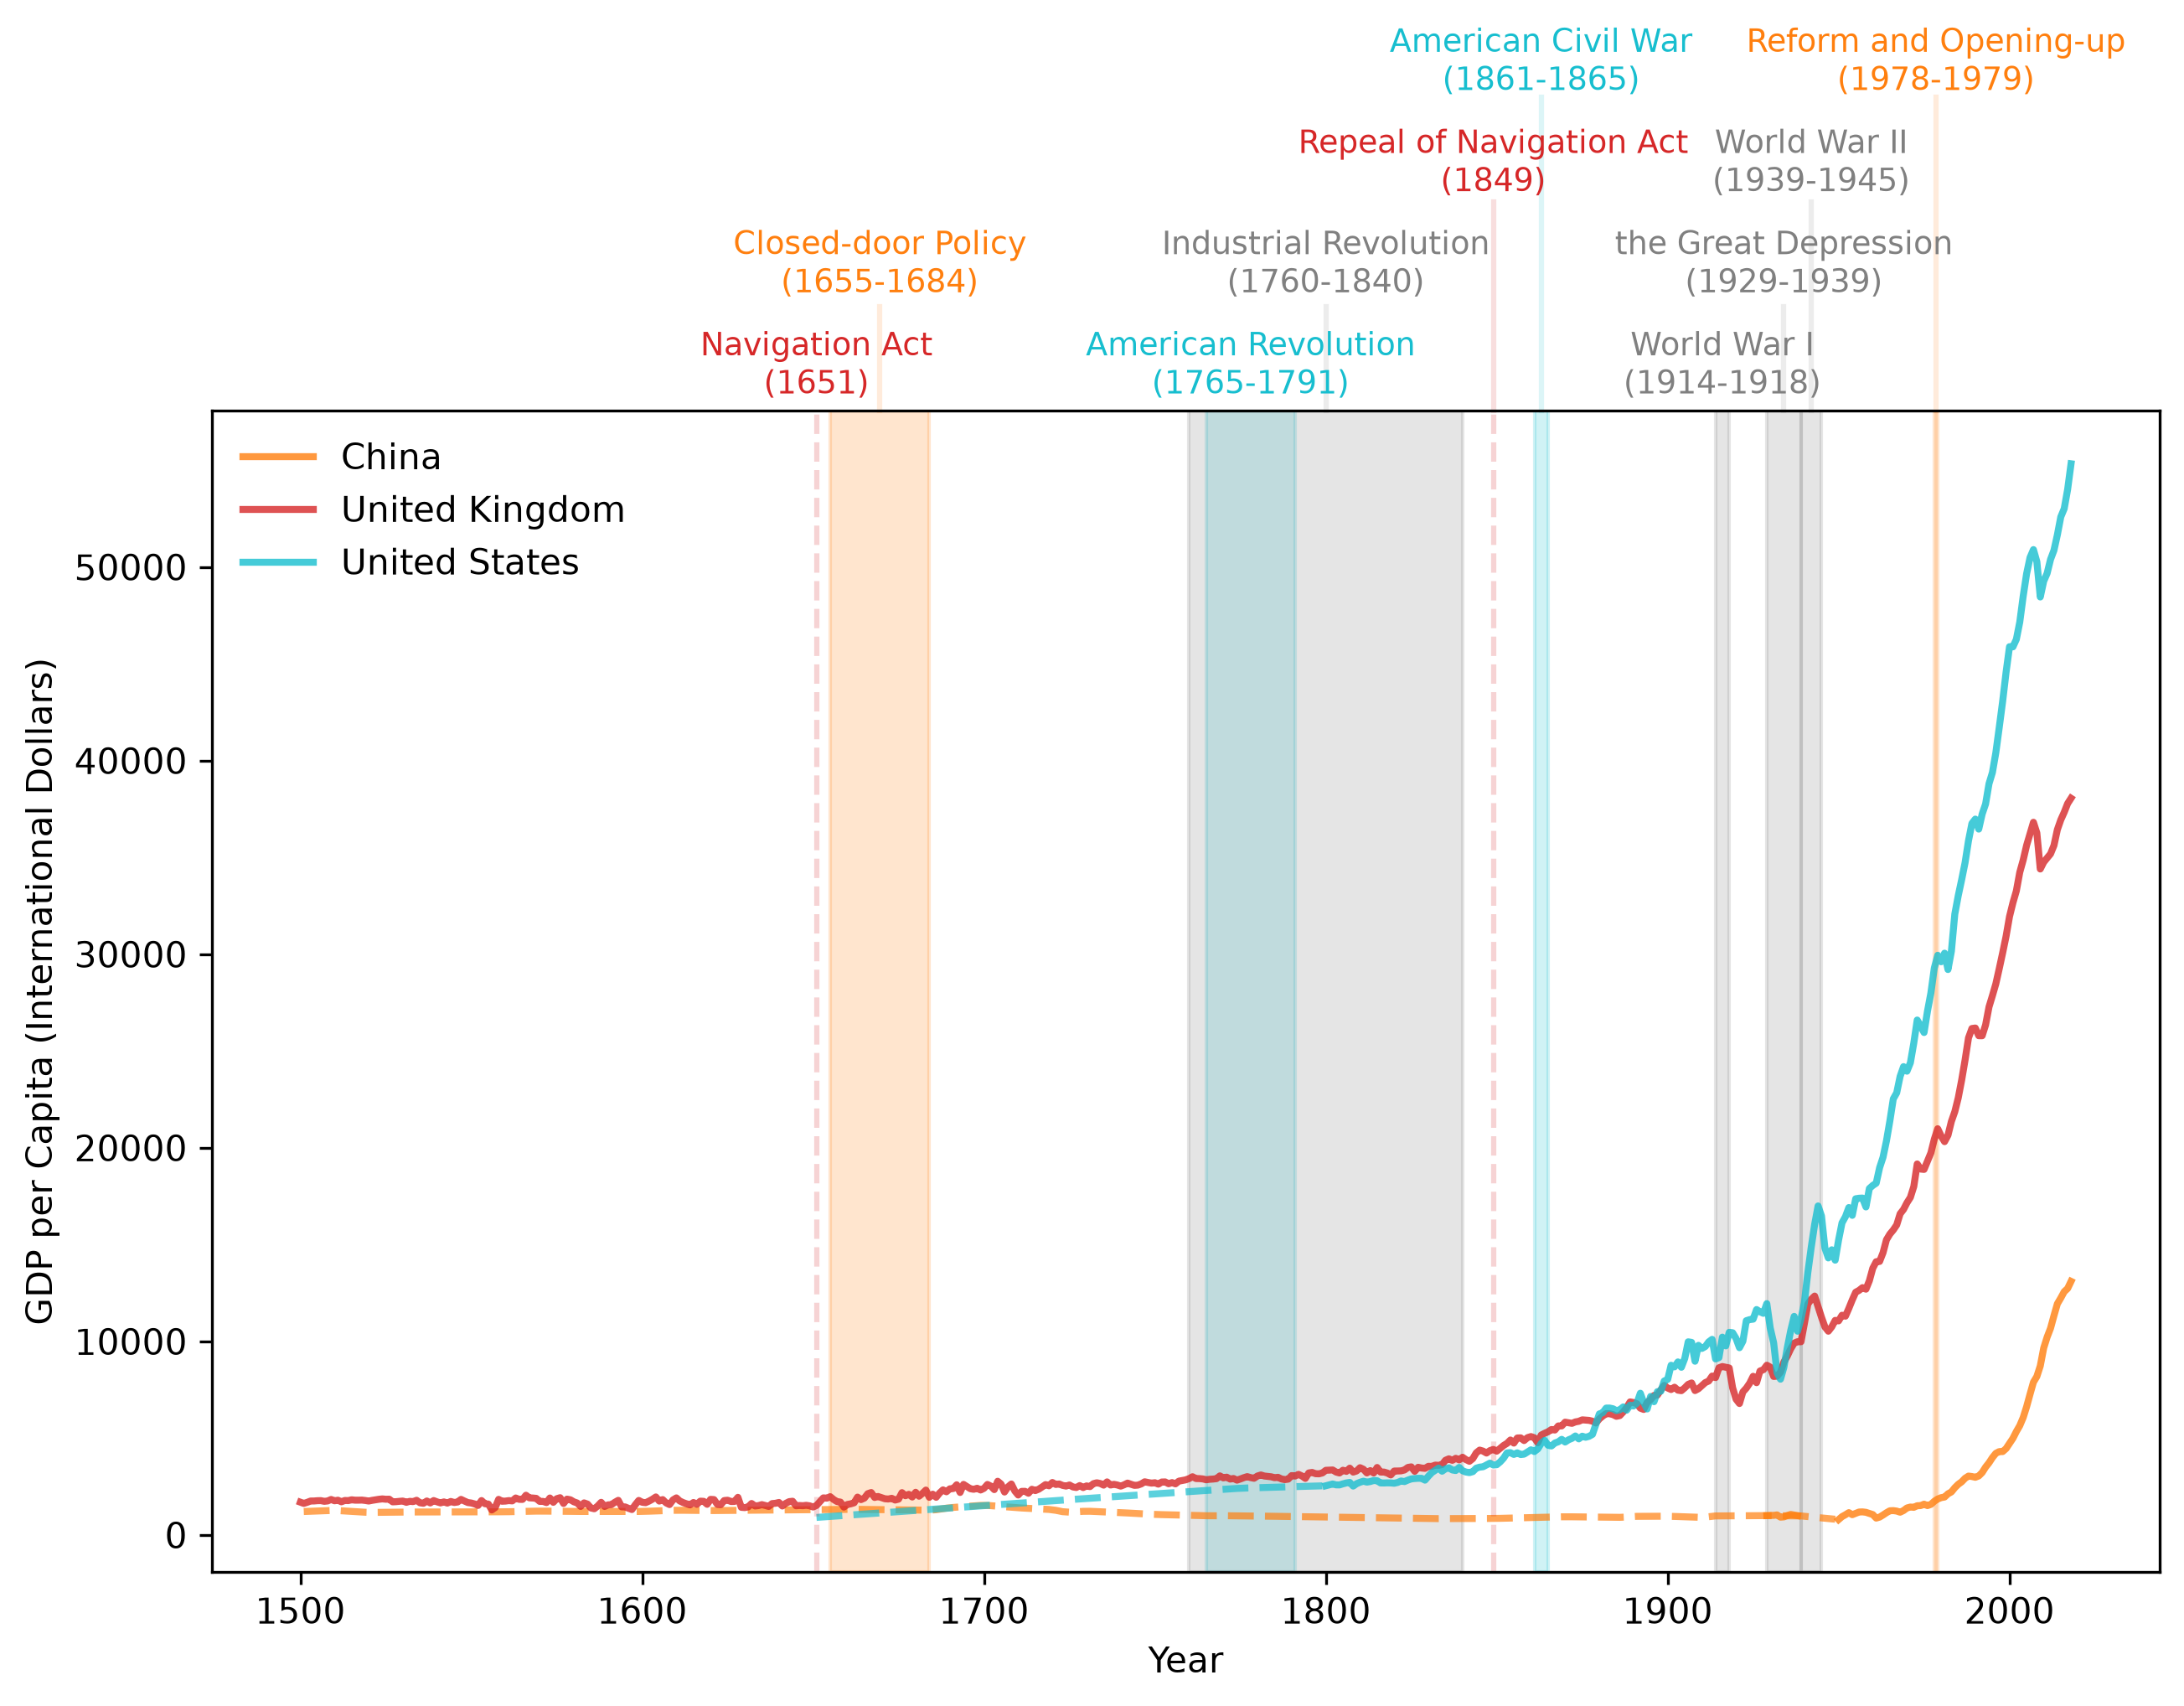

In [11]:
# Define the namedtuple for the events
Event = namedtuple("Event", ["year_range", "y_text", "text", "color", "ymax"])

fig, ax = plt.subplots(dpi=300, figsize=(10, 6))

country = ["CHN", "GBR", "USA"]
draw_interp_plots(
    gdp_pc[country].loc[1500:],
    country,
    "GDP per Capita (International Dollars)",
    "Year",
    color_mapping,
    code_to_name,
    2,
    False,
    ax,
)

# Define the parameters for the events and the text
ylim = ax.get_ylim()[1]
b_params = {"color": "grey", "alpha": 0.2}
t_params = {"fontsize": 9, "va": "center", "ha": "center"}

# Create a list of events to annotate
events = [
    Event(
        (1651,),
        ylim + ylim * 0.04,
        "Navigation Act\n(1651)",
        color_mapping["GBR"],
        1,
    ),
    Event(
        (1655, 1684),
        ylim + ylim * 0.13,
        "Closed-door Policy\n(1655-1684)",
        color_mapping["CHN"],
        1.09,
    ),
    Event(
        (1849,),
        ylim + ylim * 0.22,
        "Repeal of Navigation Act\n(1849)",
        color_mapping["GBR"],
        1.18,
    ),
    Event(
        (1765, 1791),
        ylim + ylim * 0.04,
        "American Revolution\n(1765-1791)",
        color_mapping["USA"],
        1,
    ),
    Event(
        (1861, 1865),
        ylim + ylim * 0.31,
        "American Civil War\n(1861-1865)",
        color_mapping["USA"],
        1.27,
    ),
    Event(
        (1760, 1840),
        ylim + ylim * 0.13,
        "Industrial Revolution\n(1760-1840)",
        "grey",
        1.09,
    ),
    Event(
        (1914, 1918),
        ylim + ylim * 0.04,
        "World War I\n(1914-1918)",
        "grey",
        1,
    ),
    Event(
        (1929, 1939),
        ylim + ylim * 0.13,
        "the Great Depression\n(1929-1939)",
        "grey",
        1.09,
    ),
    Event(
        (1939, 1945),
        ylim + ylim * 0.22,
        "World War II\n(1939-1945)",
        "grey",
        1.18,
    ),
    Event(
        (1978, 1979),
        ylim + ylim * 0.31,
        "Reform and Opening-up\n(1978-1979)",
        color_mapping["CHN"],
        1.27,
    ),
]


def draw_events(events, ax):
    # Iterate over events and add annotations and vertical lines
    for event in events:
        if len(event.year_range) == 1:
            event_mid = event.year_range[0]
        else:
            event_mid = sum(event.year_range) / 2
        ax.text(
            event_mid, event.y_text, event.text, color=event.color, **t_params
        )
        if len(event.year_range) > 1:
            ax.axvspan(*event.year_range, color=event.color, alpha=0.2)
        else:
            ax.axvline(
                event_mid,
                ymin=0,
                ymax=1,
                color=event.color,
                clip_on=False,
                alpha=0.2,
                linestyle="--",
            )
        ax.axvline(
            event_mid,
            ymin=1,
            ymax=event.ymax,
            color=event.color,
            clip_on=False,
            alpha=0.15,
        )


# Draw events
draw_events(events, ax)
plt.show()

We can see that most of the growth for these countries (especially the US and the UK) happened in the last 150 years, after the Industrial Revolution. Indeed, a similar effect can be seen in China; most Chinese GDP growth has happened since the Reform and Opening-up of the late 1970s.

> **Aside:** In fact, let's take a slightly close look at the rate of GDP growth per year in each of these countries, to see if we can identify key inflection points. Note that this plot is to satisfy the author's curiosity, and is not part of the QuantEcon course.

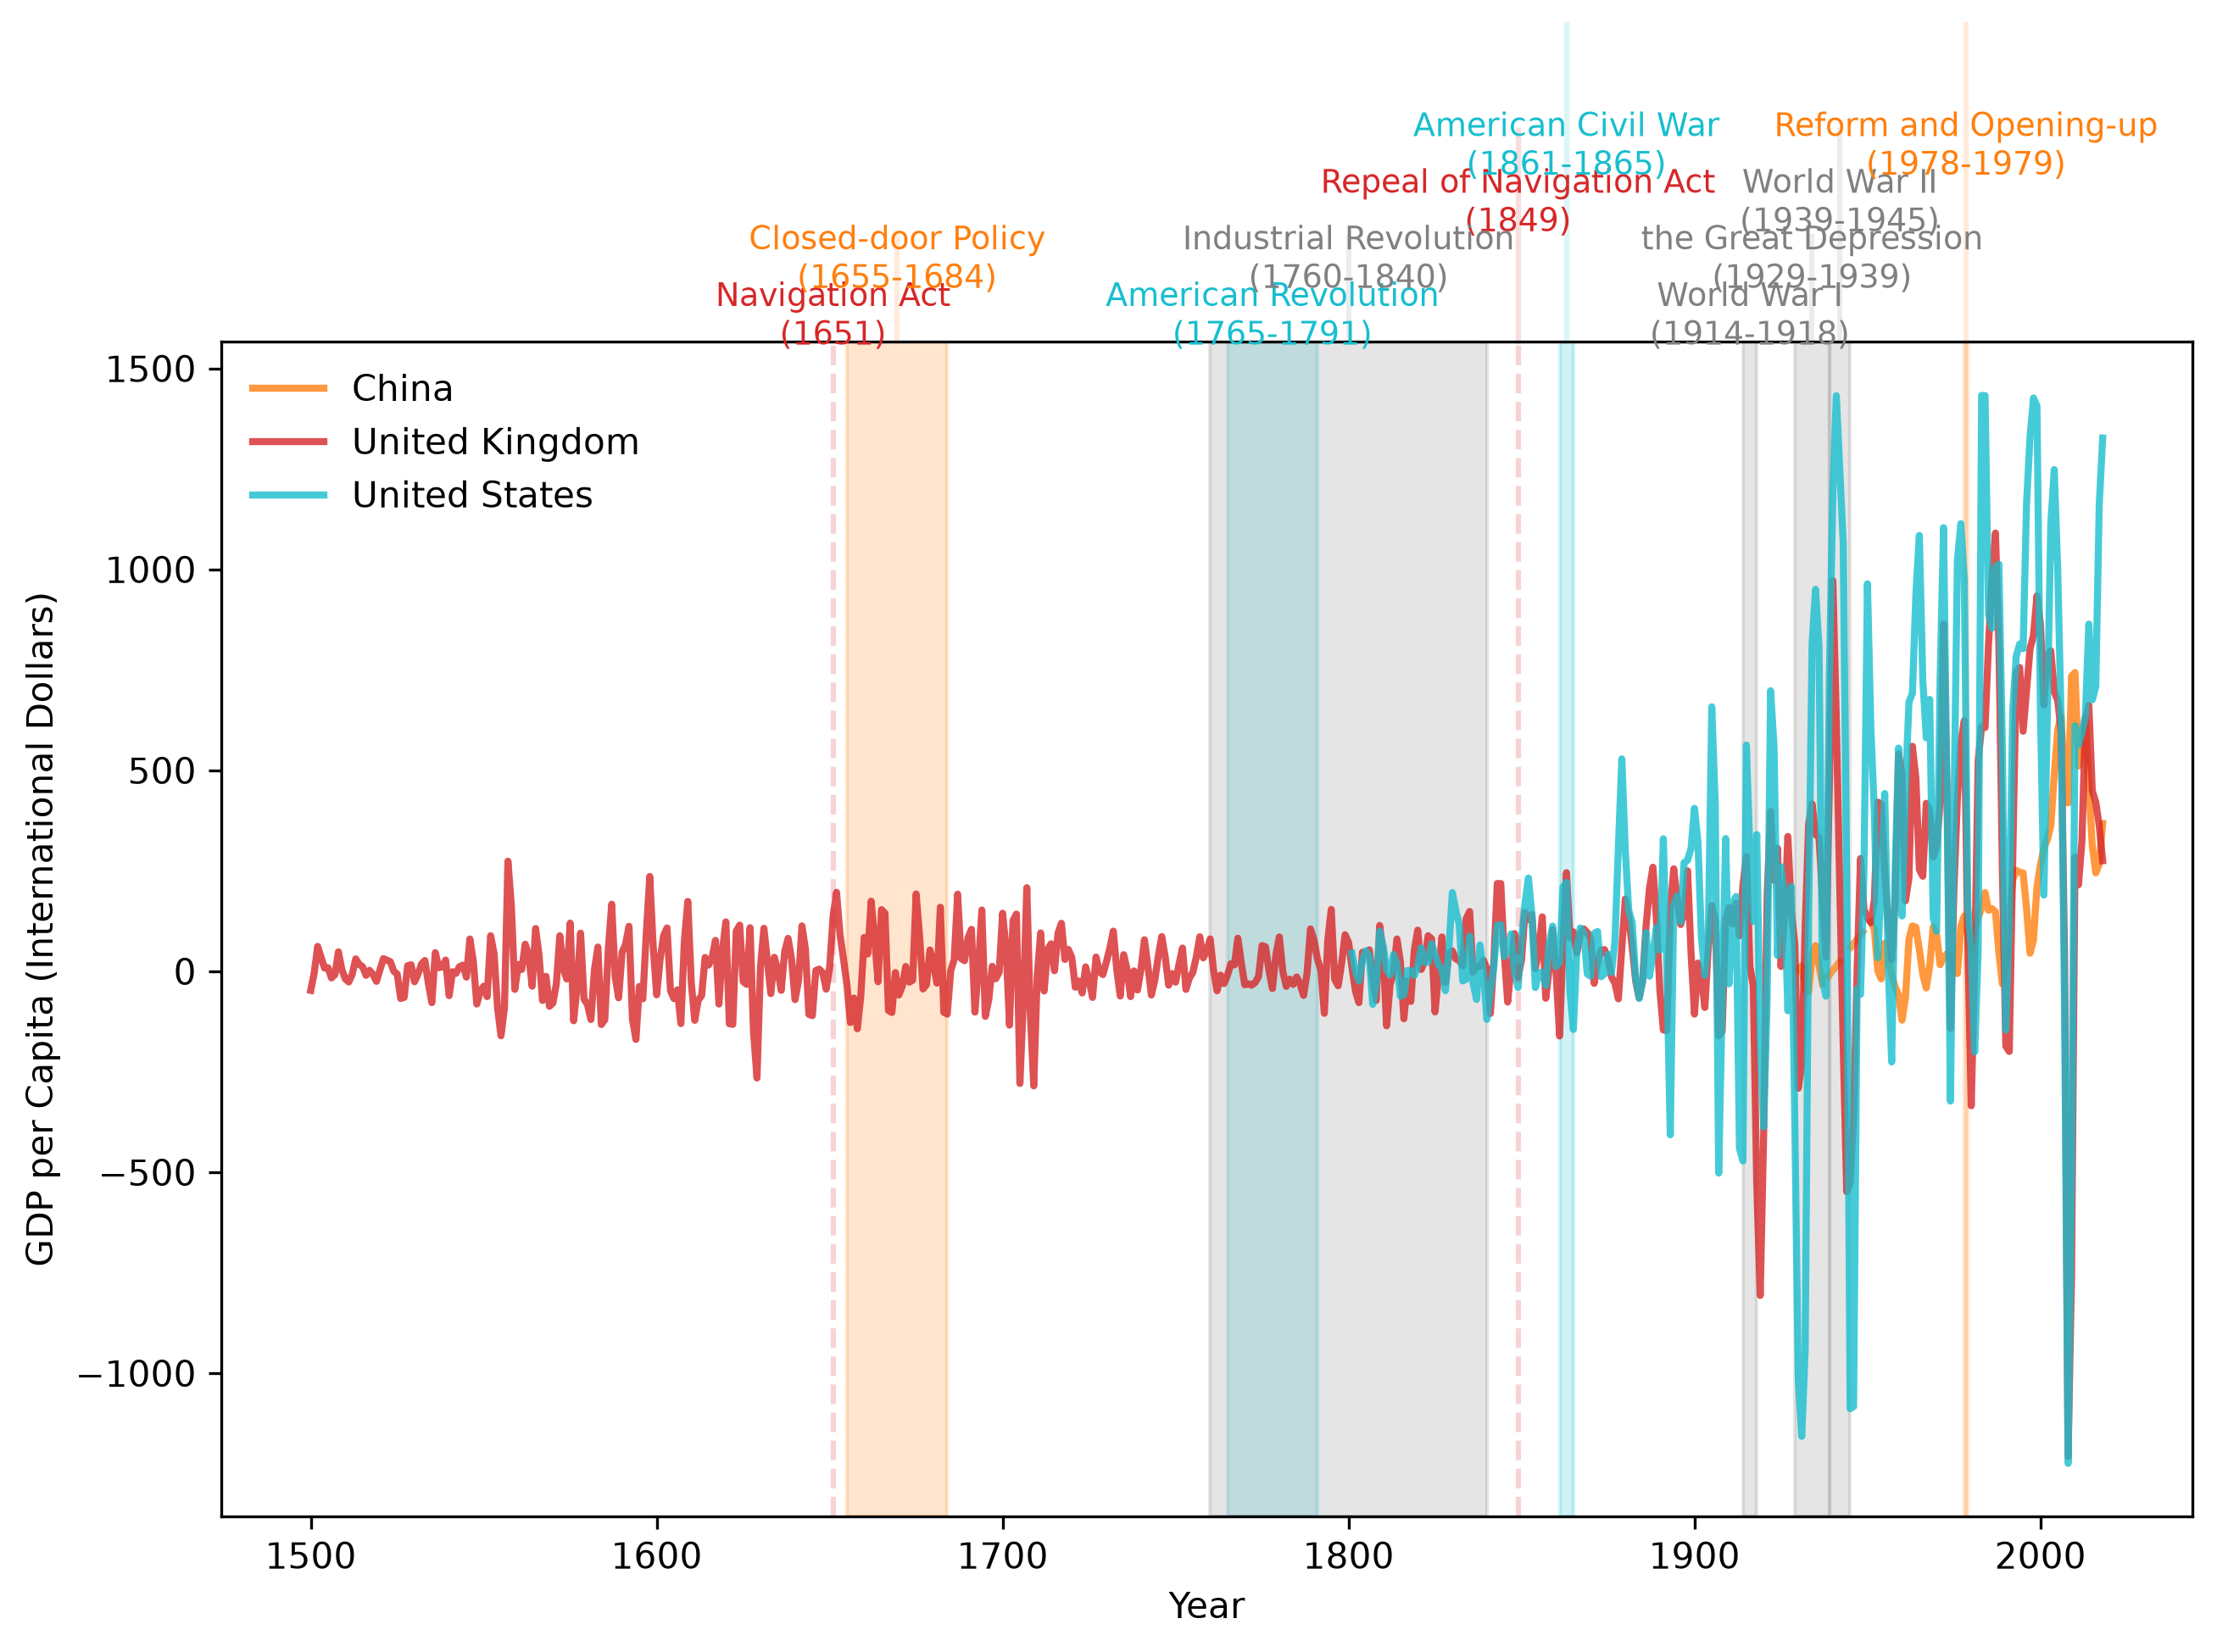

In [12]:
# Define the rate of gdp growth per year
# Compute gradient using the index as the x coordinate
grad_values = np.gradient(gdp_pc.to_numpy(), gdp_pc.index.to_numpy(), axis=0)

# Store back into a new DataFrame with matching index and columns
df_grad = pd.DataFrame(grad_values, index=gdp_pc.index, columns=gdp_pc.columns)

fig, ax = plt.subplots(dpi=300, figsize=(10, 6))

country = ["CHN", "GBR", "USA"]
draw_interp_plots(
    df_grad[country].loc[1500:],
    country,
    "GDP per Capita (International Dollars)",
    "Year",
    color_mapping,
    code_to_name,
    2,
    False,
    ax,
)

# Define the parameters for the events and the text
ylim = ax.get_ylim()[1]
b_params = {"color": "grey", "alpha": 0.2}
t_params = {"fontsize": 9, "va": "center", "ha": "center"}

# Create a list of events to annotate
events = [
    Event(
        (1651,),
        ylim + ylim * 0.04,
        "Navigation Act\n(1651)",
        color_mapping["GBR"],
        1,
    ),
    Event(
        (1655, 1684),
        ylim + ylim * 0.13,
        "Closed-door Policy\n(1655-1684)",
        color_mapping["CHN"],
        1.09,
    ),
    Event(
        (1849,),
        ylim + ylim * 0.22,
        "Repeal of Navigation Act\n(1849)",
        color_mapping["GBR"],
        1.18,
    ),
    Event(
        (1765, 1791),
        ylim + ylim * 0.04,
        "American Revolution\n(1765-1791)",
        color_mapping["USA"],
        1,
    ),
    Event(
        (1861, 1865),
        ylim + ylim * 0.31,
        "American Civil War\n(1861-1865)",
        color_mapping["USA"],
        1.27,
    ),
    Event(
        (1760, 1840),
        ylim + ylim * 0.13,
        "Industrial Revolution\n(1760-1840)",
        "grey",
        1.09,
    ),
    Event(
        (1914, 1918),
        ylim + ylim * 0.04,
        "World War I\n(1914-1918)",
        "grey",
        1,
    ),
    Event(
        (1929, 1939),
        ylim + ylim * 0.13,
        "the Great Depression\n(1929-1939)",
        "grey",
        1.09,
    ),
    Event(
        (1939, 1945),
        ylim + ylim * 0.22,
        "World War II\n(1939-1945)",
        "grey",
        1.18,
    ),
    Event(
        (1978, 1979),
        ylim + ylim * 0.31,
        "Reform and Opening-up\n(1978-1979)",
        color_mapping["CHN"],
        1.27,
    ),
]


# Draw events
draw_events(events, ax)
plt.show()

> As we can see, this is a much noisier plot, and if we dug deeper on this we'd likely want to smooth this a bit. For our current purpose of visually identifying trends this will do, however. We can clearly see that, prior to the industrial revolution, both the UK and (later) the US have relatively stagnant grown rates, averaging close to 0 change per year. After the Industrial revolution GDP rate of change starts to climb, though. WHile it is still quite noisy, there is a clear positive trend in both rates. Likewise, China also appears to have a positive trend after the late 1970s.

### 2.3.3. Focusing on China

China in particular has an interesting GDP history post 1500. We can see that the 1700s through the early 20th century saw a protracted period of economic stagnation and decline, as GDP largely decreased over this period. Let's take a closer look.

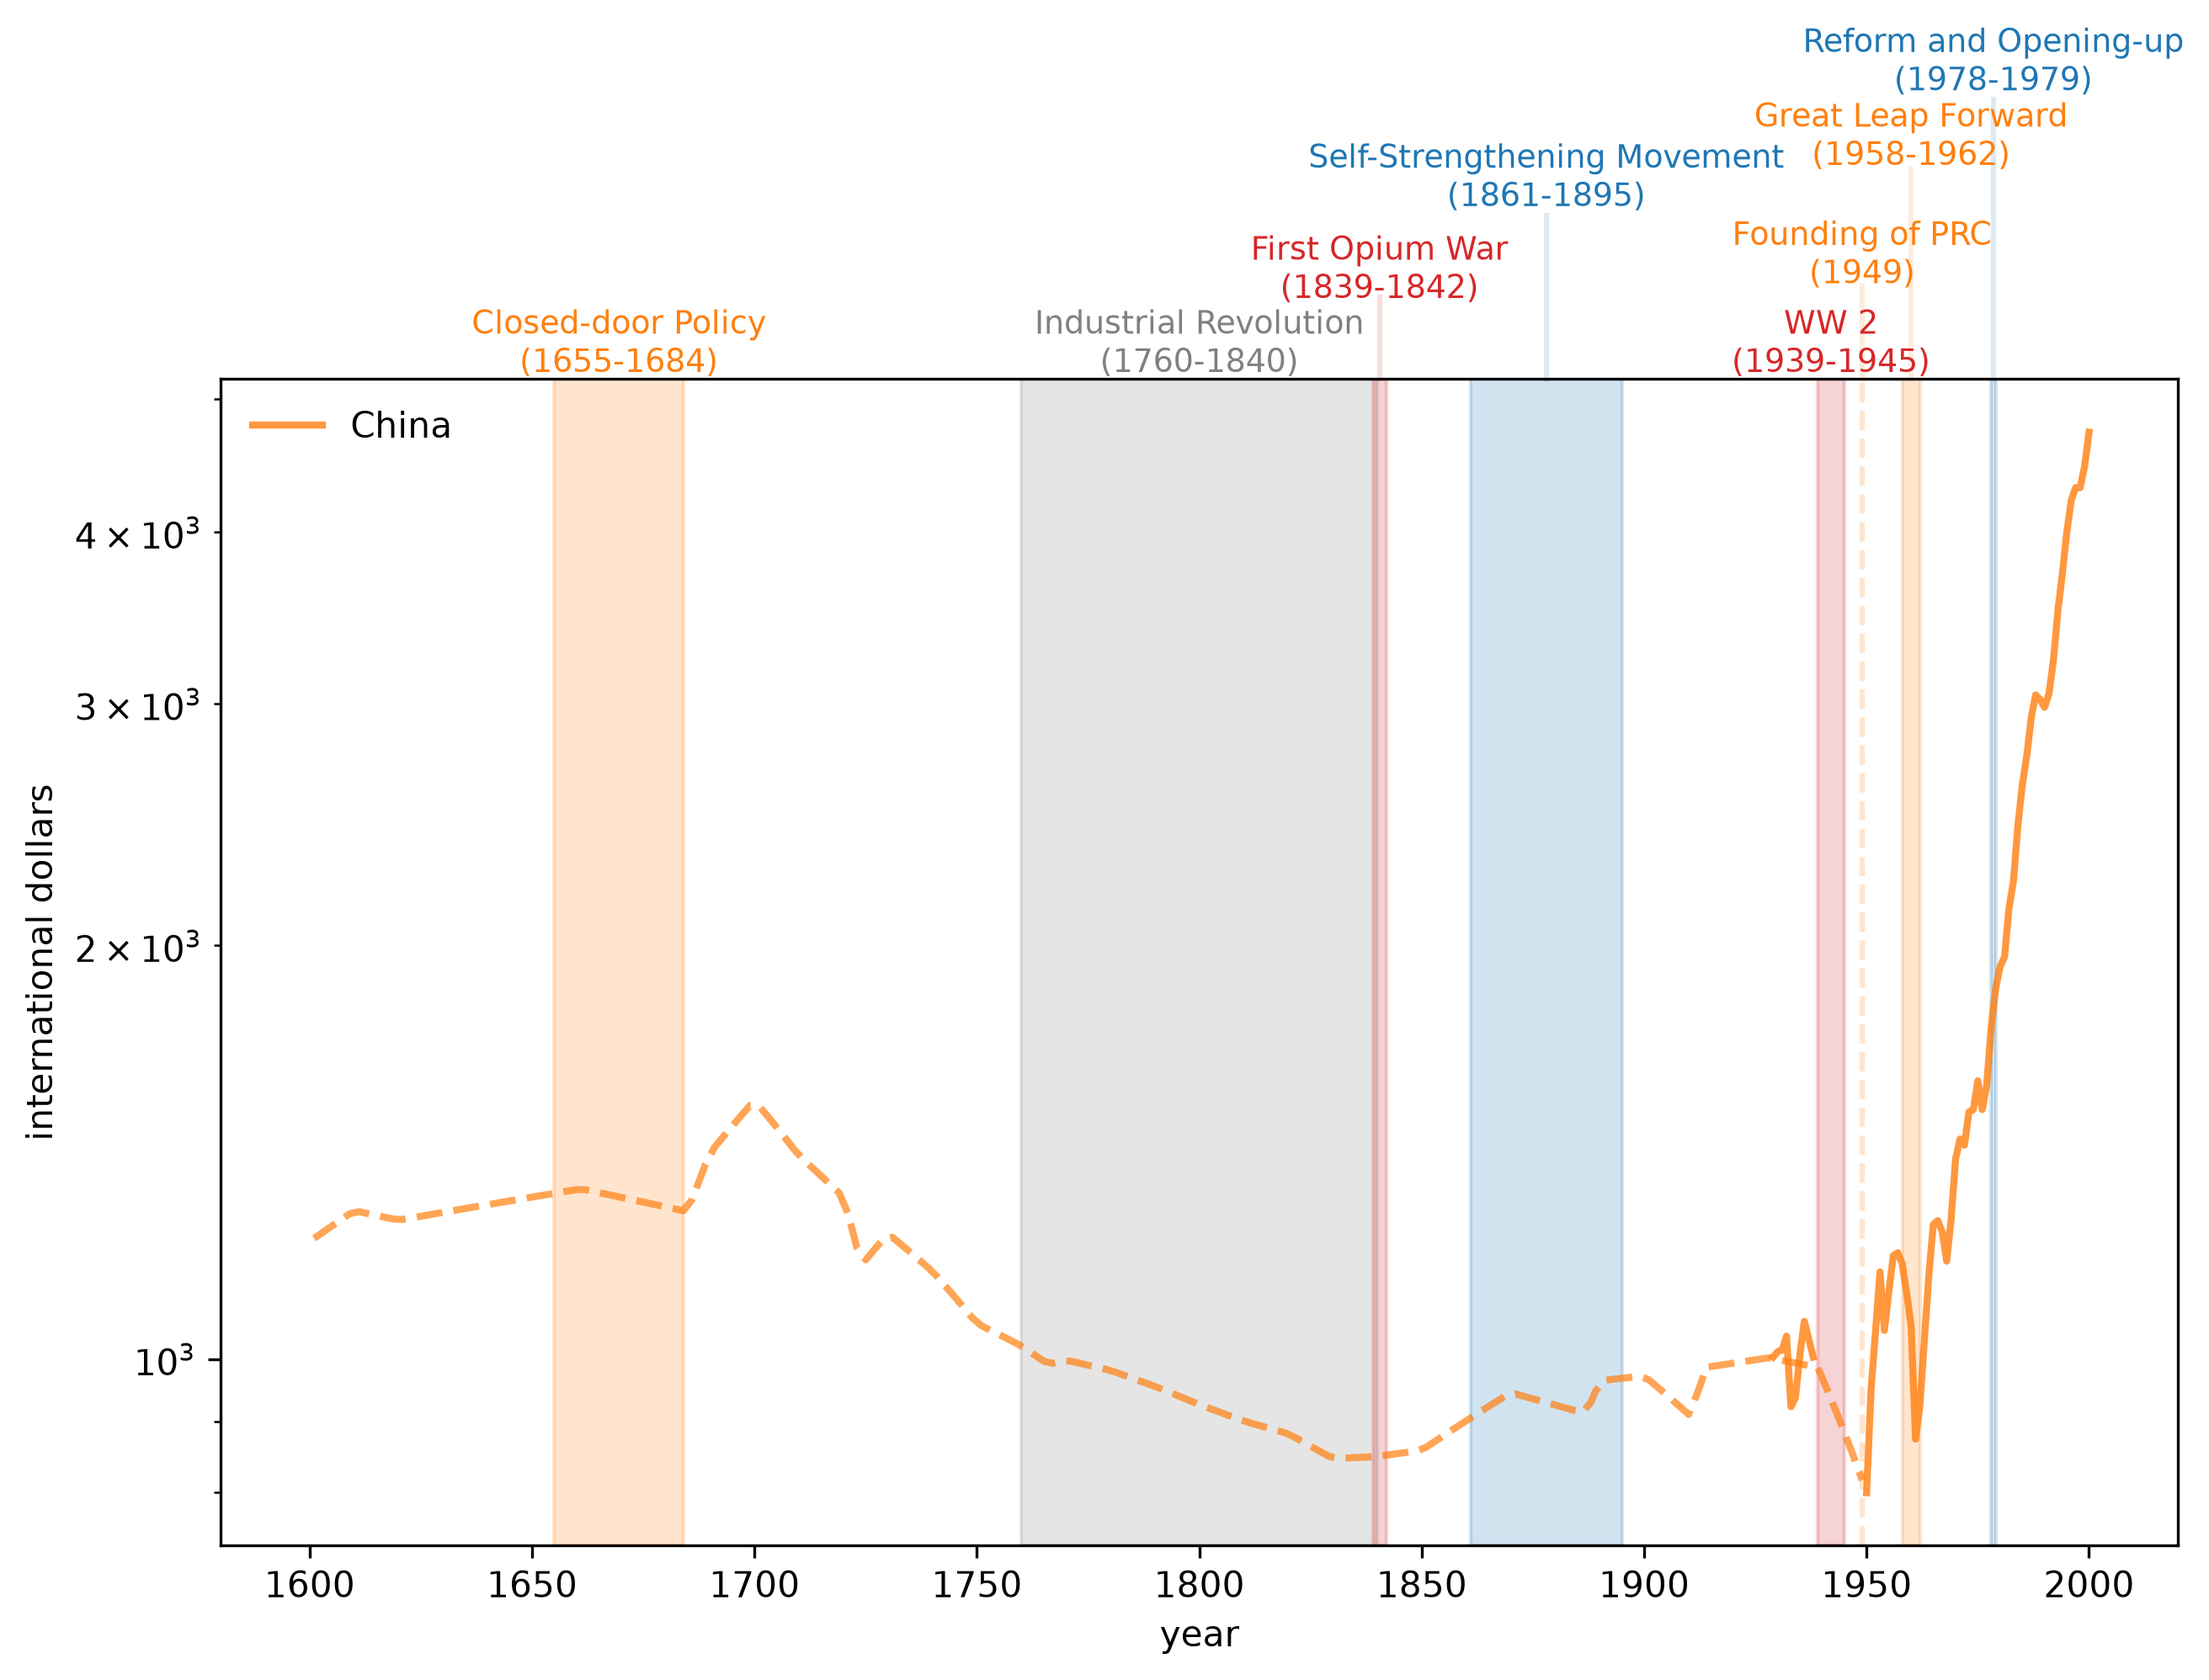

In [13]:
fig, ax = plt.subplots(dpi=300, figsize=(10, 6))

country = ["CHN"]
draw_interp_plots(
    gdp_pc[country].loc[1600:2000],
    country,
    "international dollars",
    "year",
    color_mapping,
    code_to_name,
    2,
    True,
    ax,
)

ylim = ax.get_ylim()[1]

events = [
    Event(
        (1655, 1684),
        ylim + ylim * 0.06,
        "Closed-door Policy\n(1655-1684)",
        "tab:orange",
        1,
    ),
    Event(
        (1760, 1840),
        ylim + ylim * 0.06,
        "Industrial Revolution\n(1760-1840)",
        "grey",
        1,
    ),
    Event(
        (1839, 1842),
        ylim + ylim * 0.2,
        "First Opium War\n(1839-1842)",
        "tab:red",
        1.07,
    ),
    Event(
        (1861, 1895),
        ylim + ylim * 0.4,
        "Self-Strengthening Movement\n(1861-1895)",
        "tab:blue",
        1.14,
    ),
    Event((1939, 1945), ylim + ylim * 0.06, "WW 2\n(1939-1945)", "tab:red", 1),
    Event(
        (1949,),
        ylim + ylim * 0.23,
        "Founding of PRC\n(1949)",
        color_mapping["CHN"],
        1.08,
    ),
    Event(
        (1958, 1962),
        ylim + ylim * 0.5,
        "Great Leap Forward\n(1958-1962)",
        "tab:orange",
        1.18,
    ),
    Event(
        (1978, 1979),
        ylim + ylim * 0.7,
        "Reform and Opening-up\n(1978-1979)",
        "tab:blue",
        1.24,
    ),
]

# Draw events
draw_events(events, ax)
plt.show()

We can see that the Closed-door Policy first seemed to have a negative effect on China's GDP, though this may have been inevitable. Indeed, while GDP saw an initial sharp increase after the repeal of the Closed-door Policy, this ultimately did not last. After ~1700, China's GDP steadily decreased until after the First Opium War. After this China's GDP started increasing again, through the Self-Strengthening Movement, up until shortly before the outbreak of WW2 (likely coinciding with when the Chinese civil war leading to the PRC started). After this we see a drastic decrease in GDP again until the PRC is founded, at which point GDP rises quickly. Ironically, the Great Leap Forward appears to have been a bit of a setback for GDP, but afterwards China's growth skyrockets again, apparently picking up even more steam after the late 1970s.

### 2.3.4. Focusing on the US and UK

Next we'll look at the US and the UK in more detail.

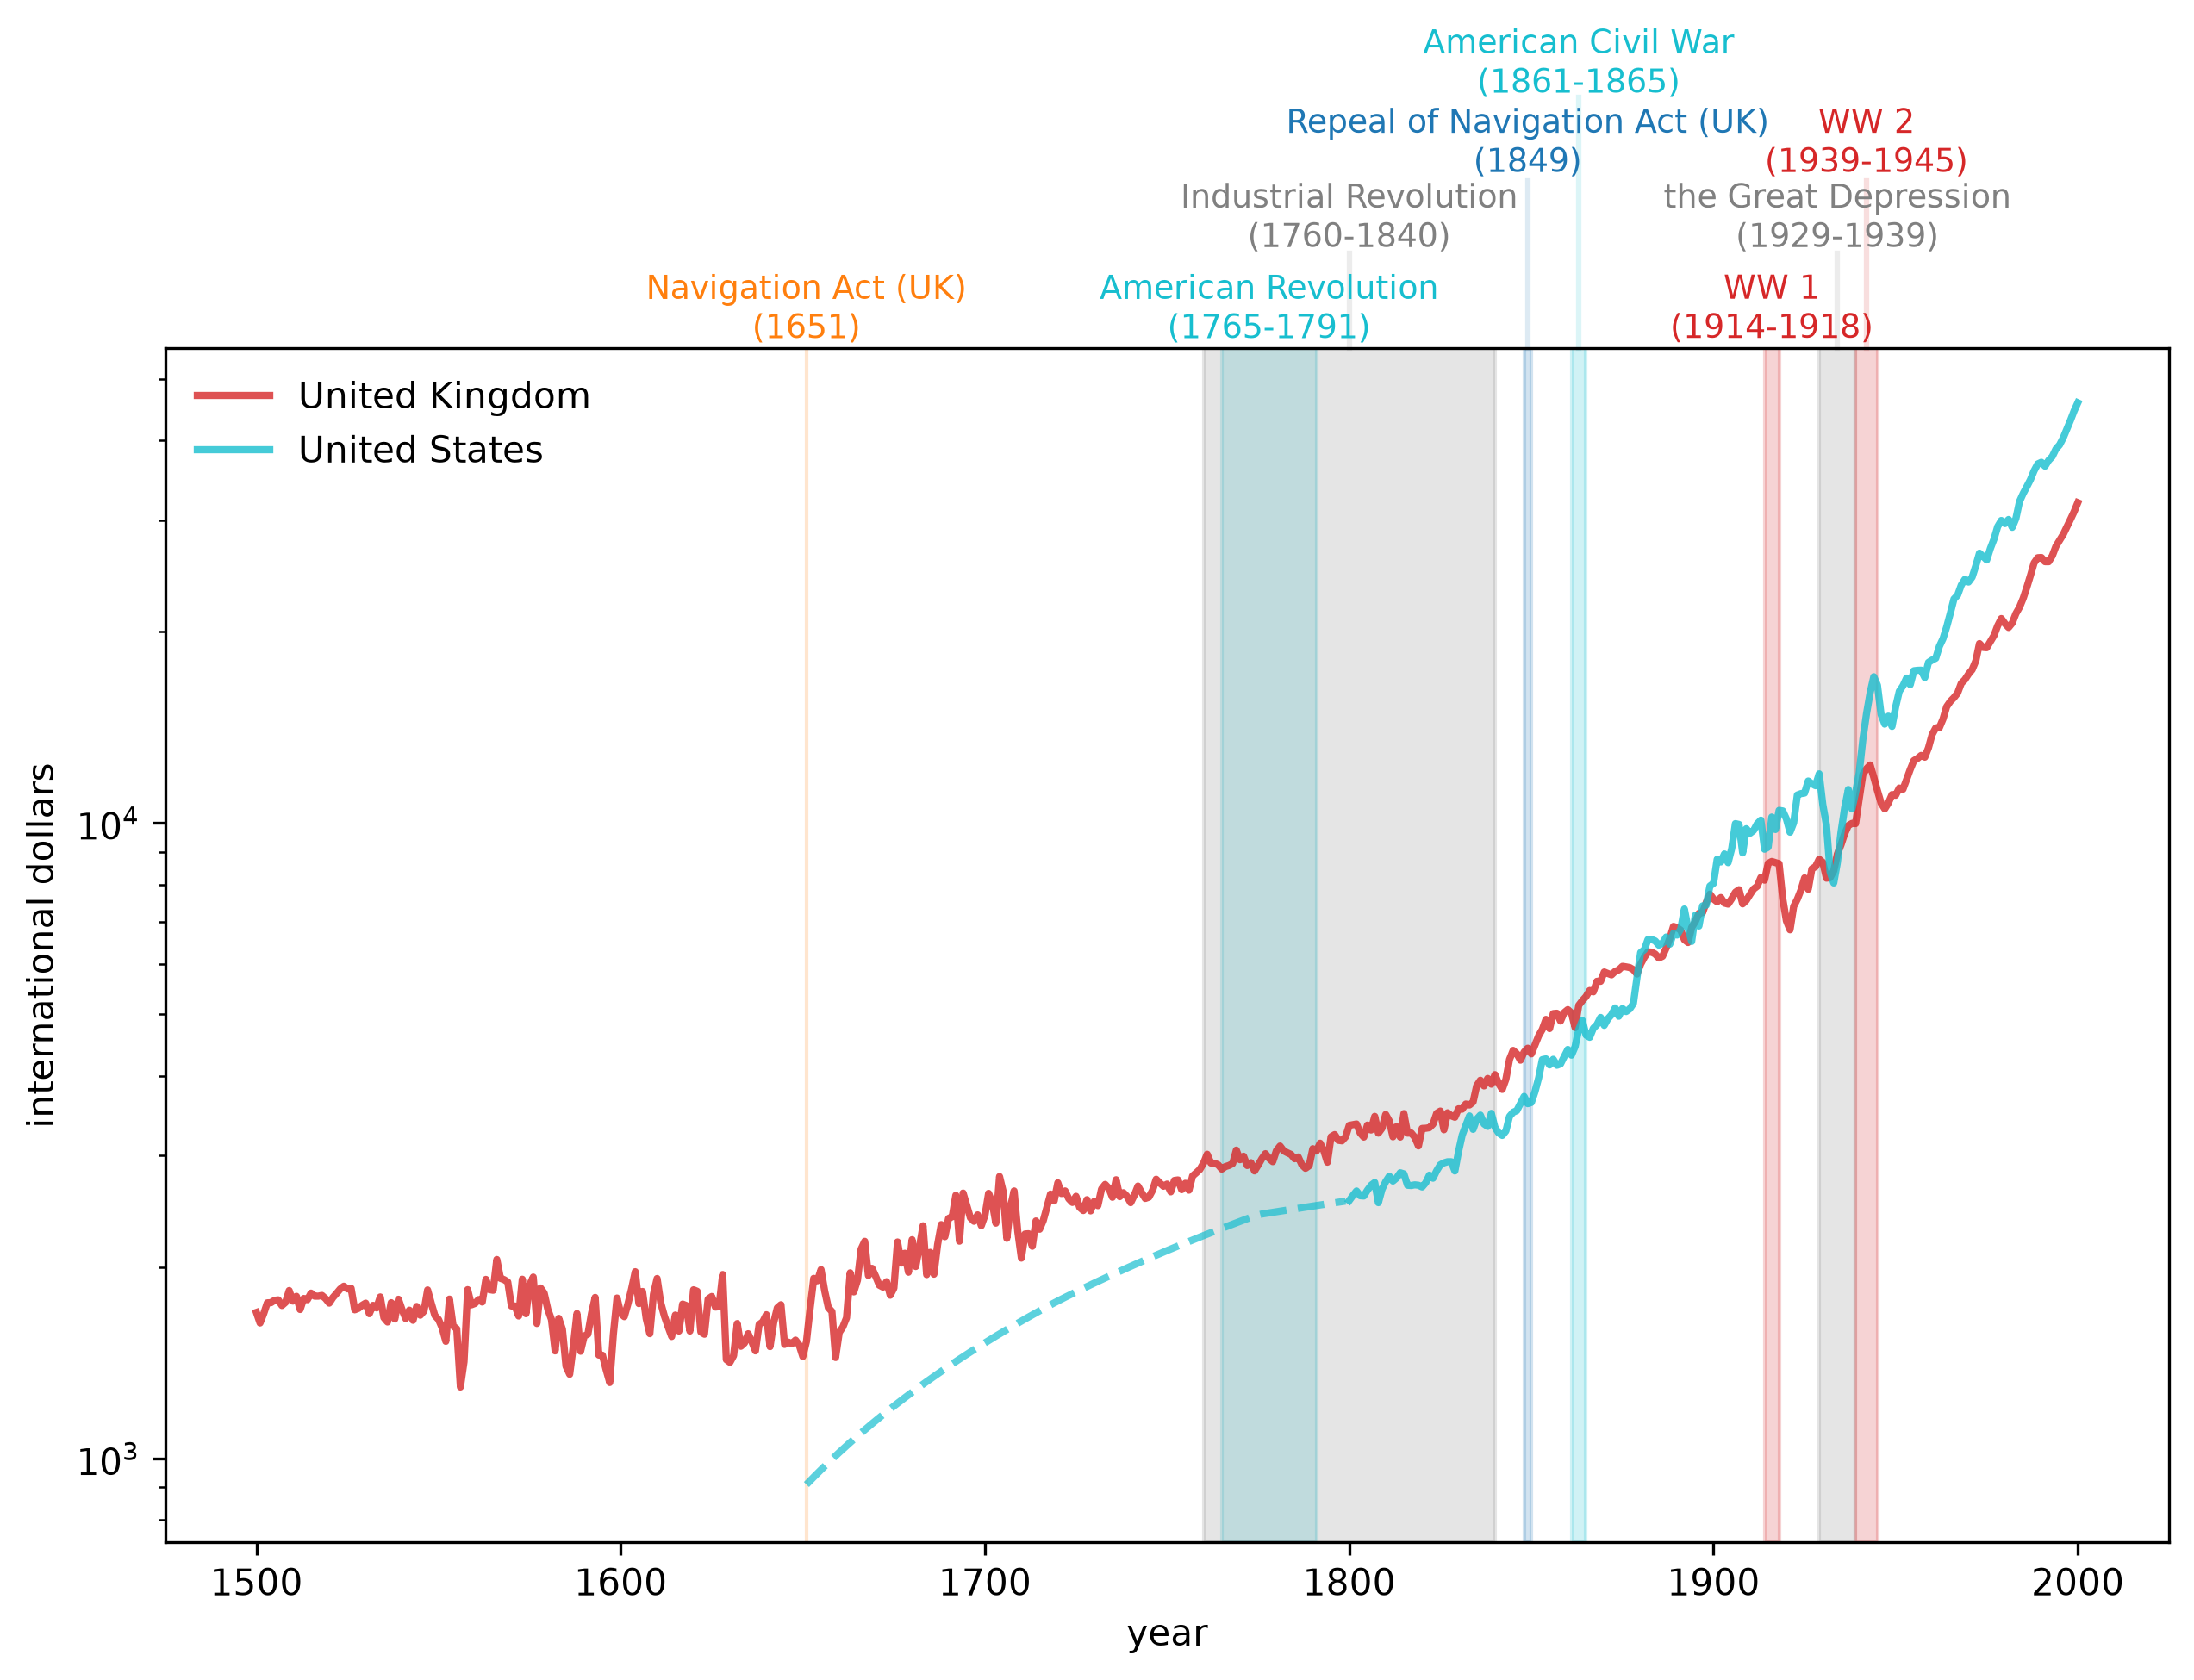

In [14]:
fig, ax = plt.subplots(dpi=300, figsize=(10, 6))

country = ["GBR", "USA"]
draw_interp_plots(
    gdp_pc[country].loc[1500:2000],
    country,
    "international dollars",
    "year",
    color_mapping,
    code_to_name,
    2,
    True,
    ax,
)

ylim = ax.get_ylim()[1]

# Create a list of data points
events = [
    Event(
        (1651, 1651),
        ylim + ylim * 0.15,
        "Navigation Act (UK)\n(1651)",
        "tab:orange",
        1,
    ),
    Event(
        (1765, 1791),
        ylim + ylim * 0.15,
        "American Revolution\n(1765-1791)",
        color_mapping["USA"],
        1,
    ),
    Event(
        (1760, 1840),
        ylim + ylim * 0.6,
        "Industrial Revolution\n(1760-1840)",
        "grey",
        1.08,
    ),
    Event(
        (1848, 1850),
        ylim + ylim * 1.1,
        "Repeal of Navigation Act (UK)\n(1849)",
        "tab:blue",
        1.14,
    ),
    Event(
        (1861, 1865),
        ylim + ylim * 1.8,
        "American Civil War\n(1861-1865)",
        color_mapping["USA"],
        1.21,
    ),
    Event((1914, 1918), ylim + ylim * 0.15, "WW 1\n(1914-1918)", "tab:red", 1),
    Event(
        (1929, 1939),
        ylim + ylim * 0.6,
        "the Great Depression\n(1929-1939)",
        "grey",
        1.08,
    ),
    Event(
        (1939, 1945), ylim + ylim * 1.1, "WW 2\n(1939-1945)", "tab:red", 1.14
    ),
]

# Draw events
draw_events(events, ax)
plt.show()

We can see that the Navigation act appears to have accelerated UK GDP per capita growth initially. The next clear inflection point happens during the industrial revolution, where we once again see a marked increase of UK GDP per capita growth rates. During this time, we also see US GDP per capita growth rates start to increase, and by the late 1800s US GDP per capita has surpassed UK GDP per capita. We additionally see that both US and UK GDP per capita initially spiked during WW1 and WW2. However these effects did not last long, and were followed by steep declines, in some cases declining more steeply than the initial growth spike.

These patterns have some possible explanations: as a war starts, production must ramp up in order to meet the military needs of affected nations. Likewise (and morbidly), throughout a war a country's population may decline as well, due to the effect of war on both the military and civilian populations leading to either death, or civilians fleeing the country. Conversely, as a war ends GDP per capita appears to decrease. This may be due to both, rising populations and a ramping down of the military industrial complex, which no longer needs to operate at full capacity.

## 2.4. GDP Growth

Next we'll focus on total GDP as a proxy for a nations geopolitical-military capabilities, as opposed to GDP per capita as a proxy for individual living standards.

In [15]:
data = load_data(version="2020")
data.set_index(["countrycode", "year"], inplace=True)
data["gdp"] = data["gdppc"] * data["pop"]
gdp = data["gdp"].unstack("countrycode")

### 2.4.1. Early Industrialization (1820 to 1940)

First let's examine GDP trends for China, the former Soviet Union, Japan, the UK, and the US.

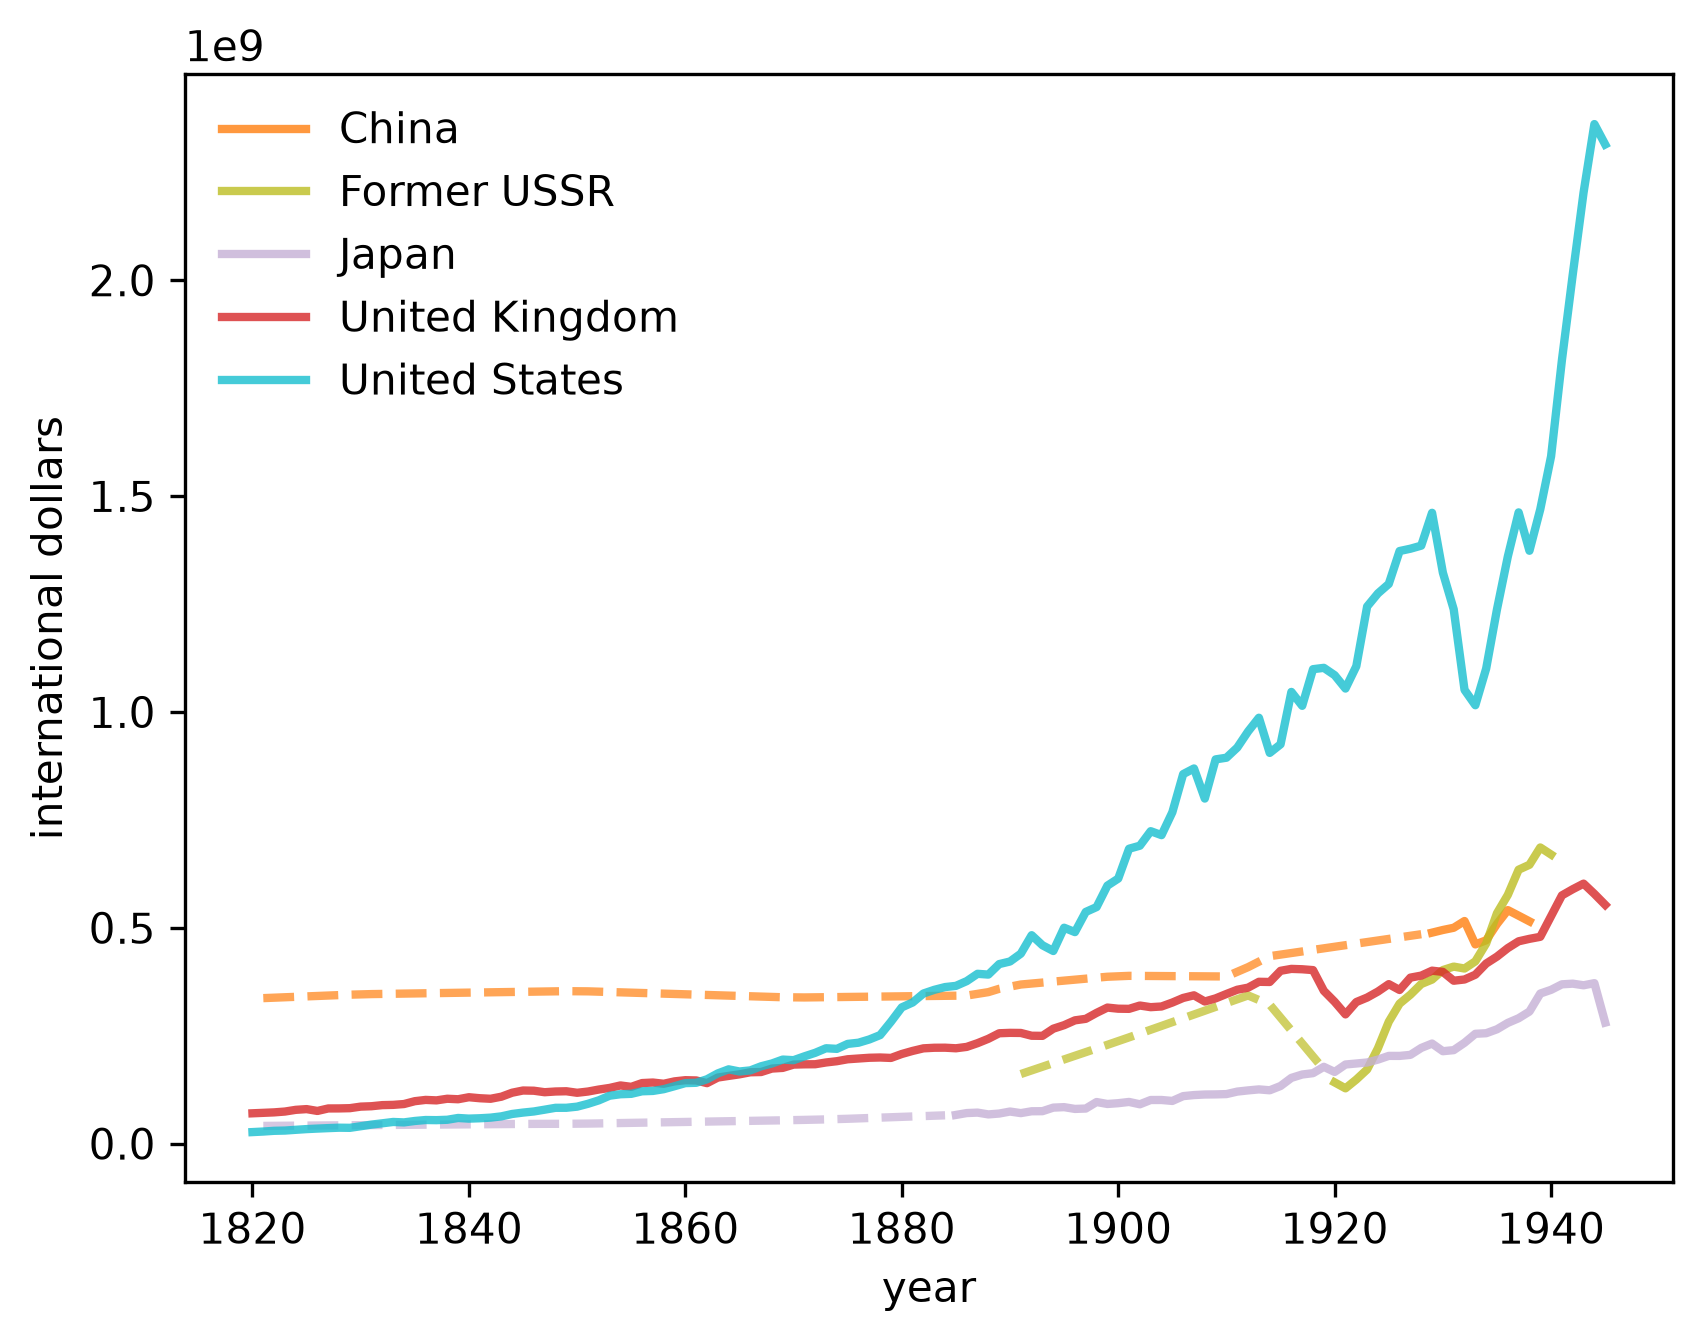

In [16]:
fig, ax = plt.subplots(dpi=300)
country = ["CHN", "SUN", "JPN", "GBR", "USA"]
start_year, end_year = (1820, 1945)
draw_interp_plots(
    gdp[country].loc[start_year:end_year],
    country,
    "international dollars",
    "year",
    color_mapping,
    code_to_name,
    2,
    False,
    ax,
)

The most notable trend is the rise of the US, surpassing the UK in the 1860s, ant China in the Early 1880s. This growth continues until the Great Depression in the first part of the 1930s, before reversing course and growing again in the second half of the 1930s.

Meanwhile, Russia saw a significant decline after WWI, and didn't start to recover until the February Revolution.

#### 2.4.1.1. Constructing a plot similar to Tooze’s

Next we build a plot similar to the figure from chapter 1 of [Tooze, 2014]. We first define a collection of countries making up the British Empire (BEM). We then assemble all the countries in our plto and plto their GDP history.

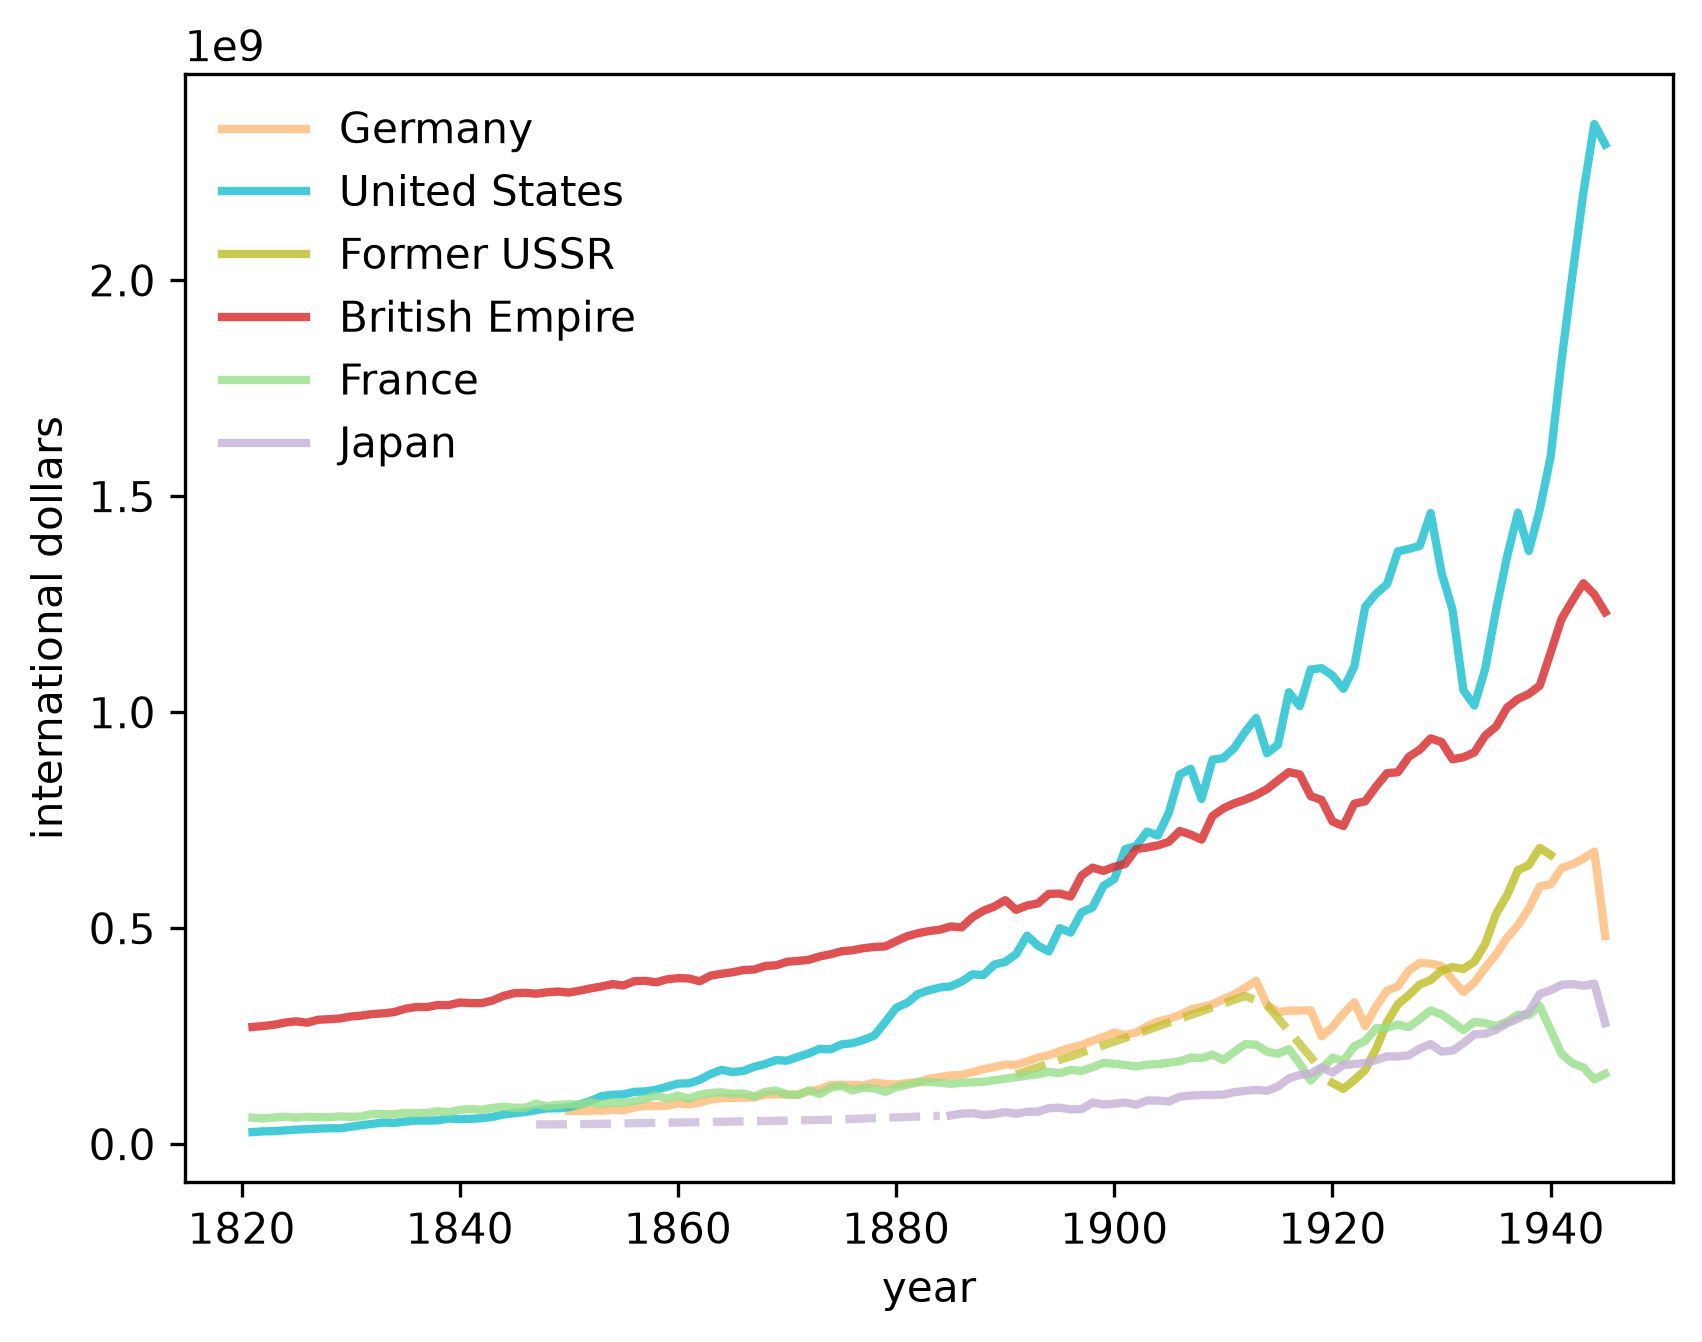

In [17]:
from pathlib import Path

BEM = ["GBR", "IND", "AUS", "NZL", "CAN", "ZAF"]
# Interpolate incomplete time-series
gdp["BEM"] = (
    gdp[BEM]
    .loc[start_year - 1 : end_year]
    .interpolate(method="index")
    .sum(axis=1)
)

# Define colour mapping and name for BEM
color_mapping["BEM"] = color_mapping[
    "GBR"
]  # Set the color to be the same as Great Britain
# Add British Empire to code_to_name
bem = pd.DataFrame(["British Empire"], index=["BEM"], columns=["country"])
bem.index.name = "countrycode"
code_to_name = pd.concat([code_to_name, bem])

fig, ax = plt.subplots(dpi=300)
country = ["DEU", "USA", "SUN", "BEM", "FRA", "JPN"]
start_year, end_year = (1821, 1945)
draw_interp_plots(
    gdp[country].loc[start_year:end_year],
    country,
    "international dollars",
    "year",
    color_mapping,
    code_to_name,
    2,
    False,
    ax,
)

output_dir = Path("./reports/figures/lecture_specific/02_long_run_growth")
if not output_dir.exists():
    output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "tooze_ch1_graph.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

We can see that US GDP quickly ramps up during this period, coming to overtake the GDP of the entire british empire by 1900. In the next section, we will pick up where Tooze's plot left off, and see how the situation has changed since the 1950s.

### 2.4.2. The Modern Era (1950 - 2020)

Next we'll continue the graph from the previous section, examining how GDP has evolved in the modern era.

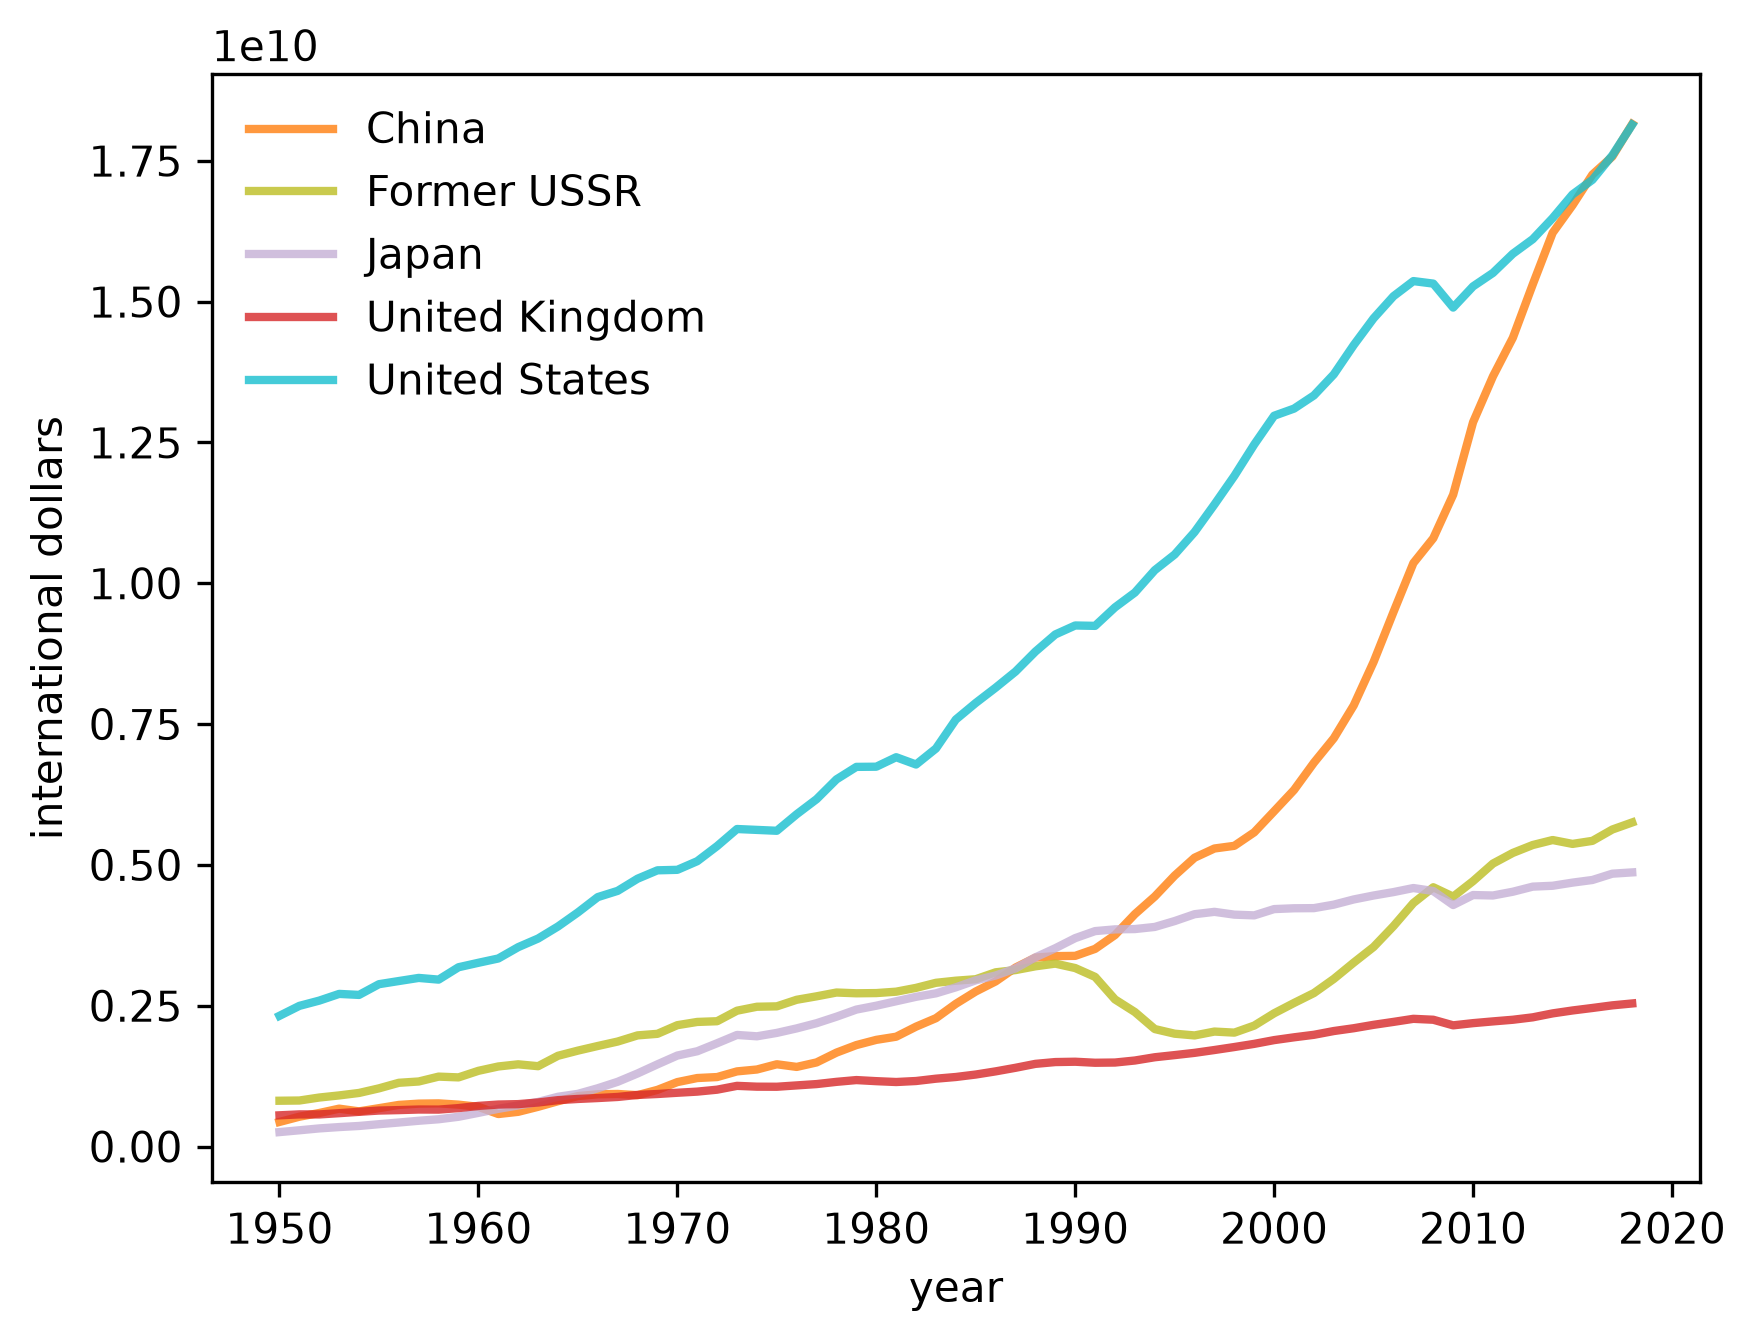

In [18]:
fig, ax = plt.subplots(dpi=300)
country = ["CHN", "SUN", "JPN", "GBR", "USA"]
start_year, end_year = (1950, 2020)
draw_interp_plots(
    gdp[country].loc[start_year:end_year],
    country,
    "international dollars",
    "year",
    color_mapping,
    code_to_name,
    2,
    False,
    ax,
)

As we can see, Chinese GDP has risen dramatically in the past 70 years, and expecially in the past 40 years or so. In the most recent 10 years or so, Chinese GDP has come into parity with US GDP, remaining competitive since about 2010. Only time will tell if this is the start of a "Chinese Century," similar to the American Century that took place after US GDP surpassed that of the British Empire.

## 2.5. Regional Analysis

We often also wnt to examine the GDP of nations outside the World Powers. For this, it is convenient to consider regional aggregations.

In [ ]:
# Load the 2020 data with the "Regional data" sheet
data = load_data(version="2020", sheet="Regional data")

# Save the data in a more convenient format for building a single table of regional GDP per capita
regionalgdp_pc = data["gdppc_2011"].copy()
regionalgdp_pc.index = pd.to_datetime(regionalgdp_pc.index, format="%Y")

# Interpolate to fill any gaps in the data
regionalgdp_pc.interpolate(method="time", inplace=True)

Region,Western Europe,Eastern Europe,Western Offshoots,Latin America,Asia (East),Asia (South and South-East),Middle East,Sub-Sahara Africa,World GDP pc
1820-01-01,2306.966690,818.000000,2513.045418,952.816821,1088.584951,929.000000,974.000000,800.000000,1101.565459
1830-01-01,2384.314573,942.000000,2833.529572,995.434209,1025.603440,929.000000,982.667458,800.000000,1142.741085
1840-01-01,2579.534884,907.000000,3153.925995,1038.039930,962.639169,929.000000,991.332542,800.000000,1183.905440
1850-01-01,2678.000000,985.000000,3474.410149,1080.657319,899.657658,929.000000,1000.000000,800.000000,1225.081067
1860-01-01,3034.000000,1358.000000,4214.440703,1588.000000,944.561264,889.678669,1082.488706,800.000000,1361.513017
1870-01-01,3301.304919,1575.000000,4647.453901,1318.541091,989.477165,850.346572,1165.000000,800.000000,1497.982325
1880-01-01,3585.154363,1886.000000,6019.123928,1495.652778,1021.757979,900.666015,1209.995893,816.665146,1735.980932
1890-01-01,4079.313847,2204.000000,6480.955612,1672.812962,1054.047632,950.999236,1255.004107,833.334854,1974.044709
1900-01-01,4724.295785,2700.000000,7740.850451,1750.626743,1086.328445,994.419007,1300.000000,850.000000,2212.043316
1910-01-01,5134.759064,2282.571503,9354.690921,2193.539665,1123.164223,1143.117595,1100.000000,900.000000,2226.604364


Next we'll compare the tiem series for `Western Offshoots` and `Sub-Saharan Africa` with regions around the world.

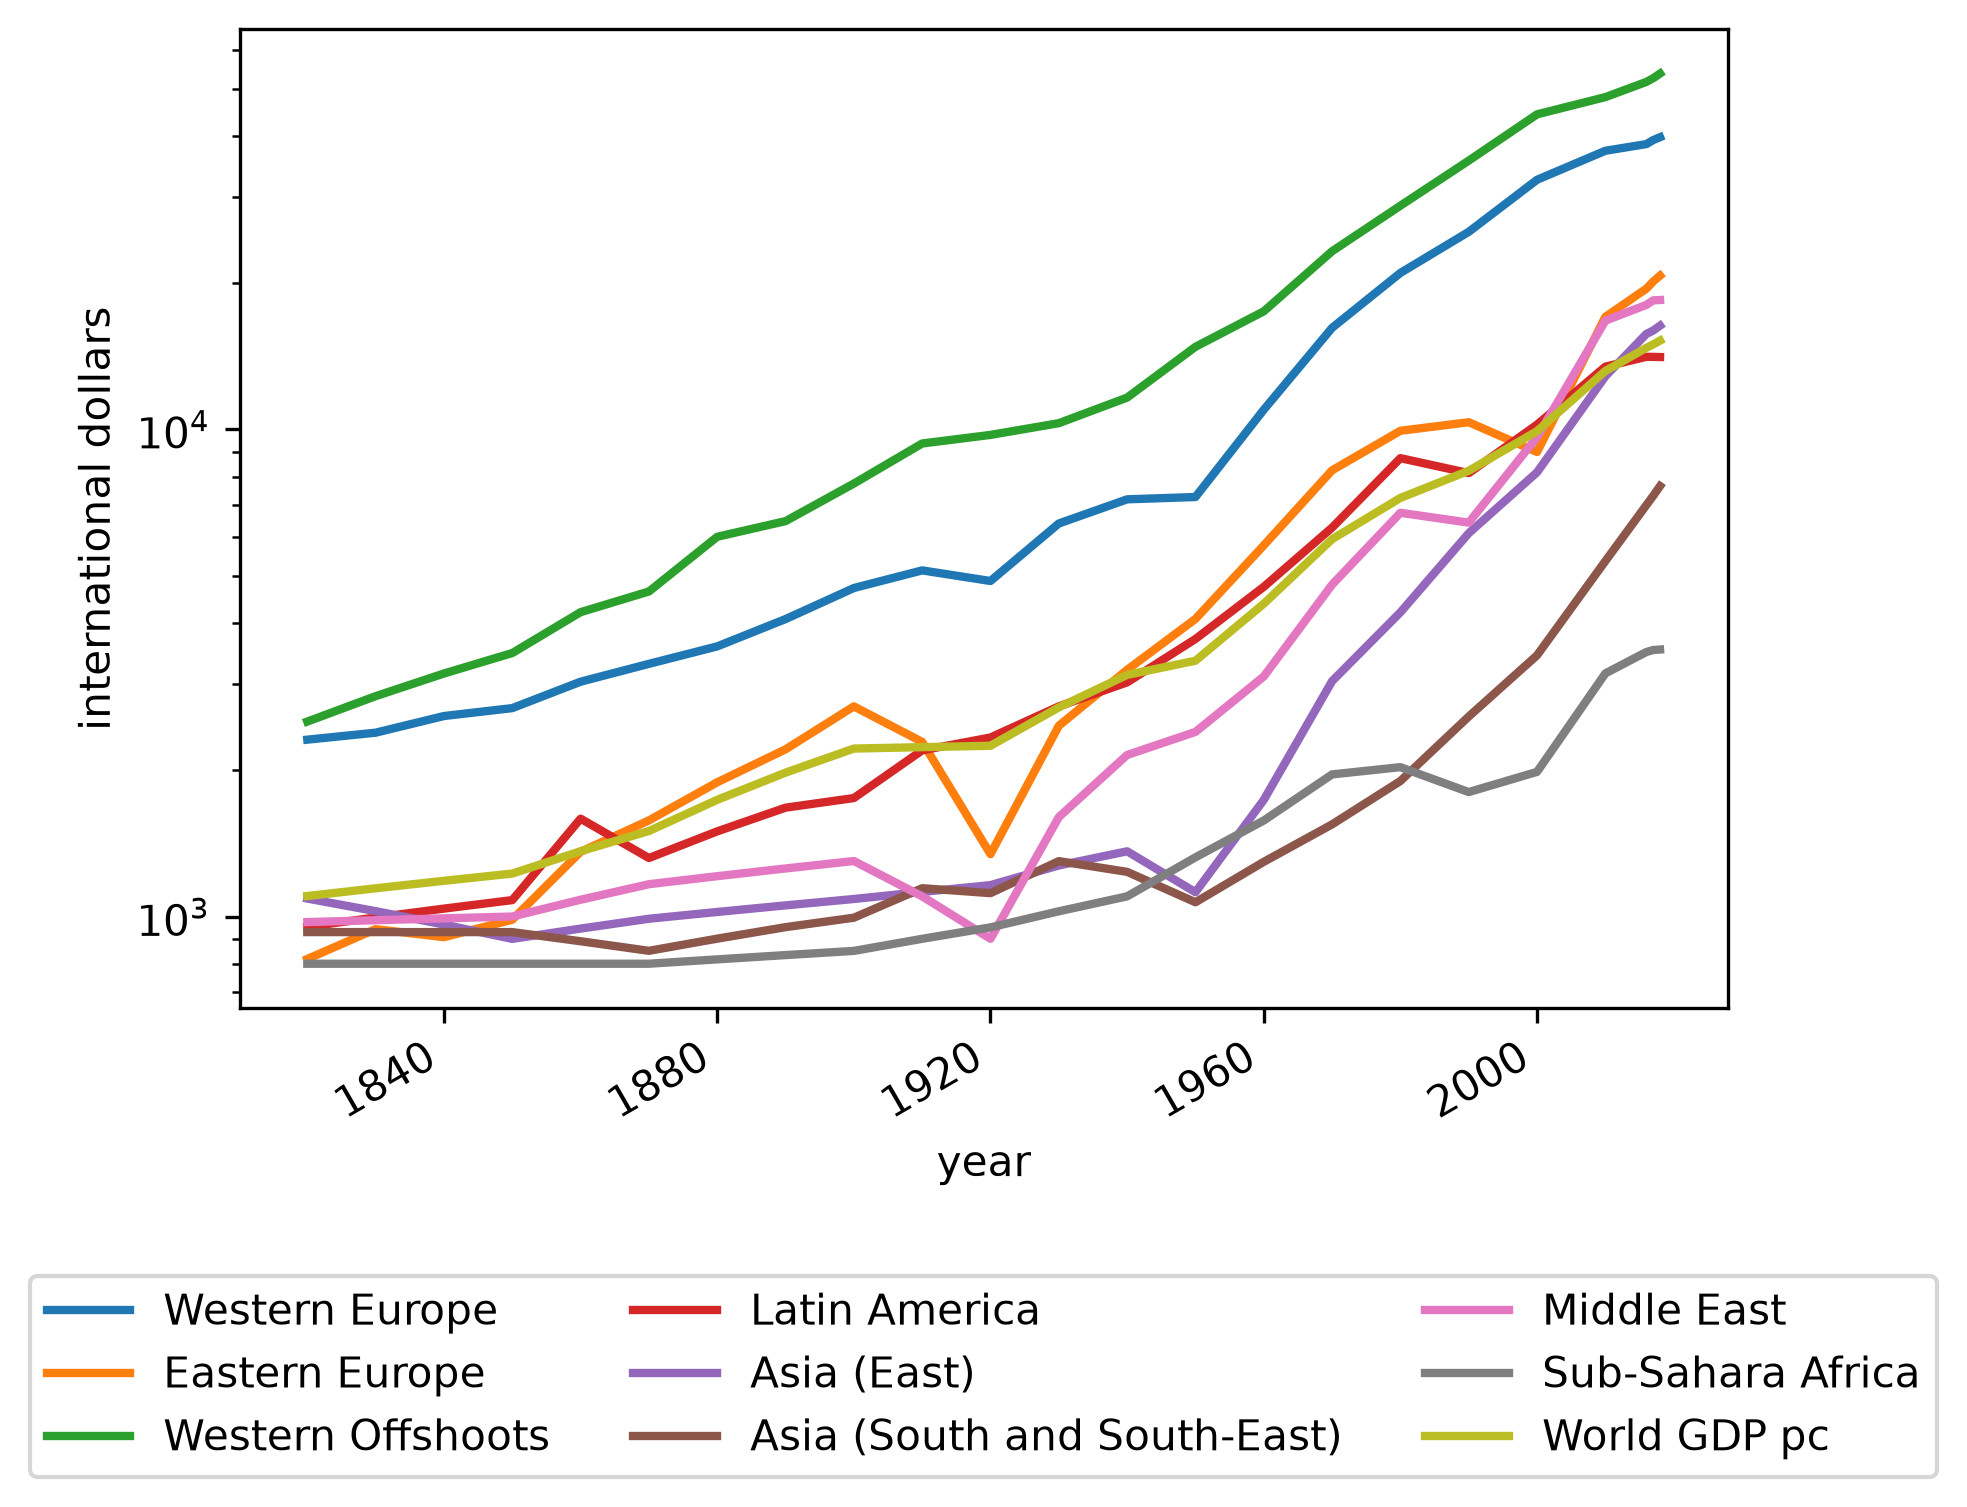

In [ ]:
fig, ax = plt.subplots(dpi=300)
regionalgdp_pc.plot(ax=ax, xlabel="year", lw=2, ylabel="international dollars")
ax.set_yscale("log")
plt.legend(loc="lower center", ncol=3, bbox_to_anchor=[0.5, -0.5])
plt.show()

We can again see that the western world diverged in GDP per capita after the Industrial Revolution, and that the rest of the world has only started to catch up since the 1950s.